# DATA 255 - Lab 2: Super Resolution
### Spring 2026 | San Jose State University
---
**Architecture:** DenoiseSRNet (ResBlocks + AMP training)

**Loss:** Charbonnier (smooth L1)

**Drive Folder:** Lab2

**Features:** AMP training, patch crops, gradient clipping, single ONNX export

## Cell 1: Install Packages

In [ ]:
!pip -q install onnx onnxruntime onnxscript
print('All packages installed! ')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 78.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 82.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.1/164.1 kB 13.0 MB/s eta 0:00:00
All packages installed! 


## Cell 2: Imports

In [ ]:
import os
import math
import glob
import time
import random
import zipfile
from pathlib import Path
import shutil
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF

from google.colab import drive

print('All imports successful!')

All imports successful!


## Cell 3: Configuration

In [ ]:
CFG = {
    'seed'           : 42,
    'drive_root'     : '/content/drive/MyDrive/Lab2',  # Your drive folder
    'work_root'      : '/content/data255_lab2',
    'run_name'       : 'lab2_run',
    'zip_names'      : [
        'LR_train.zip',  'LR_train1.zip', 'LR_train2.zip',
        'LR_train3.zip', 'LR_train4.zip',
        'HR_train.zip',  'HR_train1.zip', 'HR_train2.zip',
        'HR_train3.zip', 'HR_train4.zip',
        'LR_val.zip',    'HR_val.zip'
    ],
    'patch_size'     : 128,
    'batch_size'     : 16,
    'epochs'         : 150,
    'lr'             : 2e-4,
    'weight_decay'   : 1e-5,
    'num_workers'    : 2,
    'save_every_epoch': True,
    'channels'       : 96,
    'num_blocks'     : 16,
    'grad_clip'      : 1.0,
    'use_amp'        : True,
    'amp_dtype'      : 'bf16',
    'input_size'     : 256,
}
CONFIG = CFG
print('Configuration set!')
print(f'Drive path : {CFG["drive_root"]}')
print(f'Epochs     : {CFG["epochs"]}')
print(f'Channels   : {CFG["channels"]}')
print(f'Blocks     : {CFG["num_blocks"]}')
print(f'Batch size : {CFG["batch_size"]}')
print(f'AMP        : {CFG["use_amp"]} ({CFG["amp_dtype"]})')

Configuration set!
Drive path : /content/drive/MyDrive/Lab2
Epochs     : 150
Channels   : 96
Blocks     : 16
Batch size : 16
AMP        : True (bf16)


## Cell 4: Mount Drive + Setup

In [ ]:
drive.mount('/content/drive')

# Set seeds for reproducibility
random.seed(CFG['seed'])
np.random.seed(CFG['seed'])
torch.manual_seed(CFG['seed'])
torch.cuda.manual_seed_all(CFG['seed'])
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark     = True

device    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
amp_dtype = torch.bfloat16 if CFG['amp_dtype'] == 'bf16' else torch.float16
ckpt_dir  = f"/content/checkpoints/{CFG['run_name']}"

os.makedirs(CFG['work_root'], exist_ok=True)
os.makedirs(ckpt_dir,         exist_ok=True)

# Output folder on Drive
SAVE_DIR = os.path.join(CFG['drive_root'], 'outputs')
os.makedirs(SAVE_DIR, exist_ok=True)

print(f'Device     : {device}')
if torch.cuda.is_available():
    print(f'GPU        : {torch.cuda.get_device_name(0)}')
    print(f'GPU memory : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'Ckpt dir   : {ckpt_dir}')
print(f'Drive ok   : {os.path.exists(CFG["drive_root"])}')
print(f'Save dir   : {SAVE_DIR}')

Mounted at /content/drive
Device     : cpu
Ckpt dir   : /content/checkpoints/lab2_run
Drive ok   : True
Save dir   : /content/drive/MyDrive/Lab2/outputs


## Cell 5: Unzip ALL 12 Dataset Files

In [ ]:
def extract_zip(zip_path, out_dir):
    """Unzip archive once; skip if already done."""
    os.makedirs(out_dir, exist_ok=True)
    marker = os.path.join(out_dir, '.extracted')
    if os.path.exists(marker):
        print(f'Already extracted: {os.path.basename(zip_path)} ')
        return
    print(f'Extracting: {os.path.basename(zip_path)}...')
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(out_dir)
    Path(marker).touch()
    print(f'  Done ')

for name in CFG['zip_names']:
    zp  = os.path.join(CFG['drive_root'], name)
    dst = os.path.join(CFG['work_root'], name.replace('.zip', ''))
    if os.path.exists(zp):
        extract_zip(zp, dst)
    else:
        print(f'NOT FOUND: {zp} ')

print('\nAll zips processed!')

Already extracted: LR_train.zip 
Already extracted: LR_train1.zip 
Already extracted: LR_train2.zip 
Already extracted: LR_train3.zip 
Extracting: LR_train4.zip...
  Done 
Extracting: HR_train.zip...
  Done 
Extracting: HR_train1.zip...
  Done 
Extracting: HR_train2.zip...
  Done 
Extracting: HR_train3.zip...
  Done 
Extracting: HR_train4.zip...
  Done 
Extracting: LR_val.zip...
  Done 
Extracting: HR_val.zip...
  Done 

All zips processed!


## Cell 6: Verify Dataset & Count Images

In [ ]:
IMAGE_EXTS = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.webp')

def gather_images(folder):
    """Recursively collect all image paths under folder."""
    paths = []
    for ext in IMAGE_EXTS:
        paths.extend(glob.glob(os.path.join(folder, '**', ext), recursive=True))
    return sorted(paths)

def build_split_dirs(base, zip_list):
    return [os.path.join(base, n.replace('.zip', '')) for n in zip_list]

lr_zips = ['LR_train.zip','LR_train1.zip','LR_train2.zip','LR_train3.zip','LR_train4.zip']
hr_zips = ['HR_train.zip','HR_train1.zip','HR_train2.zip','HR_train3.zip','HR_train4.zip']

train_lr_dirs = build_split_dirs(CFG['work_root'], lr_zips)
train_hr_dirs = build_split_dirs(CFG['work_root'], hr_zips)
val_lr_dir    = os.path.join(CFG['work_root'], 'LR_val')
val_hr_dir    = os.path.join(CFG['work_root'], 'HR_val')

train_lr_files, train_hr_files = [], []
for ldir, hdir in zip(train_lr_dirs, train_hr_dirs):
    lf = gather_images(ldir)
    hf = gather_images(hdir)
    print(f'{os.path.basename(ldir)}: {len(lf)} LR | {os.path.basename(hdir)}: {len(hf)} HR')
    train_lr_files.extend(lf)
    train_hr_files.extend(hf)

val_lr_files = gather_images(val_lr_dir)
val_hr_files = gather_images(val_hr_dir)

print(f'\nTrain pairs : {len(train_lr_files)} / {len(train_hr_files)}')
print(f'Val pairs   : {len(val_lr_files)} / {len(val_hr_files)}')
assert len(train_lr_files) == len(train_hr_files), 'LR/HR count mismatch in train!'
assert len(val_lr_files)   == len(val_hr_files),   'LR/HR count mismatch in val!'
print('Dataset verified! ')

LR_train: 289 LR | HR_train: 289 HR
LR_train1: 663 LR | HR_train1: 663 HR
LR_train2: 782 LR | HR_train2: 782 HR
LR_train3: 810 LR | HR_train3: 810 HR
LR_train4: 781 LR | HR_train4: 781 HR

Train pairs : 3325 / 3325
Val pairs   : 100 / 100
Dataset verified! 


## Cell 7: Dataset Classes

In [ ]:
class PairedTrainDataset(Dataset):
    """Paired LR/HR dataset with random crop and flip/rotation augmentation."""

    def __init__(self, lr_files, hr_files, crop_size=128):
        self.lr_files  = lr_files
        self.hr_files  = hr_files
        self.crop_size = crop_size

    def __len__(self):
        return len(self.lr_files)

    def __getitem__(self, idx):
        lr = TF.to_tensor(Image.open(self.lr_files[idx]).convert('RGB'))
        hr = TF.to_tensor(Image.open(self.hr_files[idx]).convert('RGB'))

        _, h, w = lr.shape
        cs = self.crop_size

        # Pad if image smaller than crop window
        if h < cs or w < cs:
            ph = max(0, cs - h)
            pw = max(0, cs - w)
            lr = F.pad(lr, (0, pw, 0, ph), mode='reflect')
            hr = F.pad(hr, (0, pw, 0, ph), mode='reflect')
            _, h, w = lr.shape

        # Random crop
        top  = random.randint(0, h - cs)
        left = random.randint(0, w - cs)
        lr   = lr[:, top:top + cs, left:left + cs]
        hr   = hr[:, top:top + cs, left:left + cs]

        # Random horizontal flip
        if random.random() < 0.5:
            lr = torch.flip(lr, dims=[2])
            hr = torch.flip(hr, dims=[2])
        # Random vertical flip
        if random.random() < 0.5:
            lr = torch.flip(lr, dims=[1])
            hr = torch.flip(hr, dims=[1])
        # Random 90-degree rotation
        k = random.randint(0, 3)
        if k > 0:
            lr = torch.rot90(lr, k, dims=[1, 2])
            hr = torch.rot90(hr, k, dims=[1, 2])

        return lr, hr


class PairedValDataset(Dataset):
    """Paired LR/HR validation dataset (no augmentation)."""

    def __init__(self, lr_files, hr_files):
        self.lr_files = lr_files
        self.hr_files = hr_files

    def __len__(self):
        return len(self.lr_files)

    def __getitem__(self, idx):
        lr   = TF.to_tensor(Image.open(self.lr_files[idx]).convert('RGB'))
        hr   = TF.to_tensor(Image.open(self.hr_files[idx]).convert('RGB'))
        name = os.path.basename(self.lr_files[idx])
        return lr, hr, name

print('Dataset classes ready!')

Dataset classes ready!


## Cell 8: Create DataLoaders

In [ ]:
train_ds = PairedTrainDataset(
    train_lr_files,
    train_hr_files,
    crop_size=CFG['patch_size']
)
val_ds = PairedValDataset(val_lr_files, val_hr_files)

train_loader = DataLoader(
    train_ds,
    batch_size=CFG['batch_size'],
    shuffle=True,
    num_workers=CFG['num_workers'],
    pin_memory=True,
    drop_last=True
)
val_loader = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=CFG['num_workers'],
    pin_memory=True
)

print(f'Train samples : {len(train_ds)}')
print(f'Val samples   : {len(val_ds)}')
print(f'Train batches : {len(train_loader)}')
print(f'Val batches   : {len(val_loader)}')

Train samples : 3325
Val samples   : 100
Train batches : 207
Val batches   : 100


## Cell 9: Model Architecture — DenoiseSRNet
> Custom residual network for image restoration
> n_feat=96, n_blocks=16 (~4M params, NPU friendly)

In [ ]:
class ResBlock(nn.Module):
    """
    Scaled residual block.
    Scale factor 0.1 stabilizes training with many blocks.
    """
    def __init__(self, n_feat):
        super().__init__()
        self.c1    = nn.Conv2d(n_feat, n_feat, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(n_feat)
        self.c2    = nn.Conv2d(n_feat, n_feat, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(n_feat)
        self.scale = 0.1

    def forward(self, x):
        residual = F.relu(self.bn1(self.c1(x)), inplace=True)
        residual = self.bn2(self.c2(residual))
        return x + self.scale * residual


class DenoiseSRNet(nn.Module):
    """
    Custom Denoising Super Resolution Network.
    Input : [B, 3, 256, 256] degraded LR image
    Output: [B, 3, 256, 256] restored HR image

    Architecture:
    - Head: feature extraction
    - Body: n_blocks residual blocks
    - Fuse: global residual skip
    - Tail: RGB reconstruction
    - Global skip: adds input to output (residual learning)
    """
    def __init__(self, n_feat=96, n_blocks=16):
        super().__init__()
        self.head = nn.Conv2d(3,      n_feat, kernel_size=3, padding=1)
        self.body = nn.Sequential(*[ResBlock(n_feat) for _ in range(n_blocks)])
        self.fuse = nn.Conv2d(n_feat, n_feat, kernel_size=3, padding=1)
        self.tail = nn.Conv2d(n_feat, 3,      kernel_size=3, padding=1)

    def forward(self, x):
        feat = F.relu(self.head(x), inplace=True)
        out  = self.fuse(self.body(feat)) + feat  # global feature residual
        out  = self.tail(out)
        return torch.clamp(x + out, 0.0, 1.0)    # residual learning


# Build model
model = DenoiseSRNet(
    n_feat=CFG['channels'],
    n_blocks=CFG['num_blocks']
).to(device)

# Test shape
dummy = torch.randn(1, 3, 256, 256).to(device)
with torch.no_grad():
    out = model(dummy)

print(f'Input  shape     : {dummy.shape}')
print(f'Output shape     : {out.shape}')

total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total params     : {total:,}')
print(f'Trainable params : {trainable:,}')
print(f'NPU friendly     : {" Yes" if total < 10_000_000 else " Check"}')

Input  shape     : torch.Size([1, 3, 256, 256])
Output shape     : torch.Size([1, 3, 256, 256])
Total params     : 2,751,747
Trainable params : 2,751,747
NPU friendly     :  Yes


## Cell 10: Test ONNX Export Early
> Professor Tip 1: Always test before training!

In [ ]:
import onnx

TEST_ONNX   = '/content/test_export.onnx'
model.eval()
dummy_input = torch.randn(1, 3, 256, 256).to(device)

try:
    torch.onnx.export(
        model,
        dummy_input,
        TEST_ONNX,
        export_params=True,
        opset_version=11,
        do_constant_folding=True,
        input_names=['input'],
        output_names=['output'],
        dynamic_axes=None,
        verbose=False
    )
    # Merge into single file
    onnx_model = onnx.load(TEST_ONNX)
    onnx.save_model(onnx_model, TEST_ONNX, save_as_external_data=False)
    onnx.checker.check_model(onnx.load(TEST_ONNX))
    size_mb = os.path.getsize(TEST_ONNX) / 1e6
    print(f'ONNX test export  :  Success')
    print(f'Size              : {size_mb:.1f} MB')
    print(f'Single file       : {" Yes" if size_mb > 1 else " Still split"}')
    print(f'Safe to train!    : ')
except Exception as e:
    print(f'ONNX export FAILED: {e}')
    print('Fix model before training!')

W0407 01:46:07.112000 19851 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0407 01:46:08.043000 19851 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0407 01:46:08.045000 19851 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' 

Applied 32 of general pattern rewrite rules.
ONNX test export  :  Success
Size              : 11.1 MB
Single file       :  Yes
Safe to train!    : 


## Cell 11: Loss Function & PSNR
> Charbonnier loss (smooth L1) + PSNR metric

In [ ]:
def charbonnier_loss(pred, target, eps=1e-6):
    """
    Charbonnier loss: smooth approximation of L1.
    More robust to outliers than MSE.
    Better edge preservation than plain L1.
    """
    diff = pred - target
    return torch.mean(torch.sqrt(diff * diff + eps))


def compute_psnr(pred, target):
    """
    Compute PSNR in dB. Images in [0,1].
    Higher = better. Target > 23 dB.
    """
    with torch.no_grad():
        mse = torch.mean((pred.clamp(0,1) - target.clamp(0,1)) ** 2)
        if mse == 0:
            return float('inf')
        return 20 * math.log10(1.0 / math.sqrt(mse.item()))


def run_validation(model, val_loader):
    """Run full validation and return avg loss and avg PSNR."""
    model.eval()
    total_loss = 0.0
    total_psnr = 0.0

    with torch.no_grad():
        for lr_img, hr_img, _ in val_loader:
            lr_img = lr_img.to(device)
            hr_img = hr_img.to(device)
            pred   = model(lr_img)
            total_loss += charbonnier_loss(pred, hr_img).item()
            total_psnr += compute_psnr(pred[0], hr_img[0])

    return total_loss / len(val_loader), total_psnr / len(val_loader)


print('Loss : Charbonnier (smooth L1)')
print('PSNR : computed on [0,1] range')

Loss : Charbonnier (smooth L1)
PSNR : computed on [0,1] range


## Cell 12: Optimizer & Scheduler

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=CFG['lr'],
    weight_decay=CFG['weight_decay']
)

# CosineAnnealingLR for smooth LR decay
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CFG['epochs'],
    eta_min=1e-6
)

# AMP scaler for mixed precision training
scaler = torch.amp.GradScaler(
    'cuda',
    enabled=(device.type == 'cuda' and
             amp_dtype == torch.float16 and
             CFG['use_amp'])
)

print('Optimizer : Adam')
print('Scheduler : CosineAnnealingLR')
print(f'AMP       : {scaler.is_enabled()}')

Optimizer : Adam
Scheduler : CosineAnnealingLR
AMP       : False


## Cell 13: Training Loop
> AMP training + gradient clipping + checkpoints every epoch

In [ ]:
best_psnr = -float('inf')
history   = []

print('=' * 65)
print('Starting Training — DenoiseSRNet')
print('Charbonnier loss | AMP | 150 epochs')
print('=' * 65)

for epoch in range(1, CFG['epochs'] + 1):
    model.train()
    t0           = time.time()
    epoch_loss   = 0.0
    use_amp_flag = device.type == 'cuda' and CFG['use_amp']

    for lr_img, hr_img in train_loader:
        lr_img = lr_img.to(device, non_blocking=True)
        hr_img = hr_img.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type='cuda', dtype=amp_dtype, enabled=use_amp_flag):
            pred = model(lr_img)
            loss = charbonnier_loss(pred, hr_img)

        if scaler.is_enabled():
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optimizer.step()

        epoch_loss += loss.item()

    scheduler.step()
    avg_train_loss     = epoch_loss / len(train_loader)
    val_loss, val_psnr = run_validation(model, val_loader)
    elapsed            = time.time() - t0
    cur_lr             = optimizer.param_groups[0]['lr']

    record = dict(
        epoch=epoch, train_loss=avg_train_loss,
        val_loss=val_loss, val_psnr=val_psnr,
        lr=cur_lr, time_sec=elapsed
    )
    history.append(record)

    print(
        f'Ep {epoch:03d}/{CFG["epochs"]} '
        f'train={avg_train_loss:.6f} '
        f'val={val_loss:.6f} '
        f'psnr={val_psnr:.3f} '
        f'lr={cur_lr:.2e} '
        f't={elapsed:.1f}s'
    )

    # Save latest checkpoint
    ckpt_payload = dict(
        epoch=epoch,
        model=model.state_dict(),
        optimizer=optimizer.state_dict(),
        scheduler=scheduler.state_dict(),
        history=history,
        config=CFG
    )
    torch.save(ckpt_payload, os.path.join(ckpt_dir, 'last.pth'))

    # Save every epoch checkpoint
    if CFG['save_every_epoch']:
        torch.save(
            dict(epoch=epoch, model=model.state_dict(),
                 val_psnr=val_psnr, history=history, config=CFG),
            os.path.join(ckpt_dir, f'epoch_{epoch:03d}.pth')
        )

    # Save best model
    if val_psnr > best_psnr:
        best_psnr = val_psnr
        best_path = os.path.join(ckpt_dir, 'best.pth')
        torch.save(
            dict(epoch=epoch, model=model.state_dict(),
                 val_psnr=val_psnr, history=history, config=CFG),
            best_path
        )
        print(f'  --> New best! PSNR: {best_psnr:.3f} dB saved!')
        # Also copy to Drive immediately
        shutil.copy(best_path, os.path.join(SAVE_DIR, 'best_model.pth'))

print('=' * 65)
print(f'Training complete! Best PSNR: {best_psnr:.3f} dB')
print('=' * 65)

Starting Training — DenoiseSRNet
Charbonnier loss | AMP | 150 epochs
Ep 001/150 train=0.046325 val=0.060921 psnr=21.466 lr=2.00e-04 t=28.8s
  --> New best! PSNR: 21.466 dB saved!
Ep 002/150 train=0.040470 val=0.060045 psnr=21.556 lr=2.00e-04 t=21.4s
  --> New best! PSNR: 21.556 dB saved!
Ep 003/150 train=0.039839 val=0.059469 psnr=21.598 lr=2.00e-04 t=21.5s
  --> New best! PSNR: 21.598 dB saved!
Ep 004/150 train=0.039789 val=0.059368 psnr=21.625 lr=2.00e-04 t=21.6s
  --> New best! PSNR: 21.625 dB saved!
Ep 005/150 train=0.039731 val=0.059149 psnr=21.648 lr=1.99e-04 t=21.6s
  --> New best! PSNR: 21.648 dB saved!
Ep 006/150 train=0.039182 val=0.058942 psnr=21.665 lr=1.99e-04 t=21.6s
  --> New best! PSNR: 21.665 dB saved!
Ep 007/150 train=0.039015 val=0.058553 psnr=21.692 lr=1.99e-04 t=21.6s
  --> New best! PSNR: 21.692 dB saved!
Ep 008/150 train=0.039134 val=0.058333 psnr=21.722 lr=1.99e-04 t=21.5s
  --> New best! PSNR: 21.722 dB saved!
Ep 009/150 train=0.038888 val=0.058298 psnr=21.730 

## Cell 14: Plot Training Curves

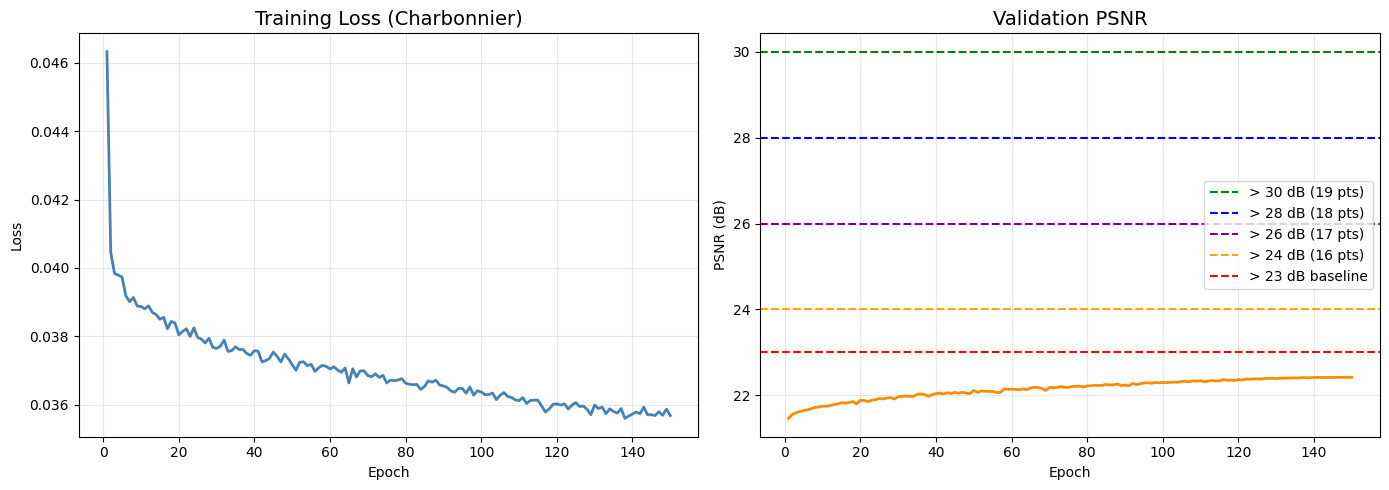

Curves saved to Drive!


In [ ]:
import matplotlib.pyplot as plt

epochs_list = [r['epoch']      for r in history]
train_losses= [r['train_loss'] for r in history]
val_psnrs   = [r['val_psnr']   for r in history]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_list, train_losses, color='steelblue', linewidth=2)
ax1.set_title('Training Loss (Charbonnier)', fontsize=14)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, alpha=0.3)

ax2.plot(epochs_list, val_psnrs, color='darkorange', linewidth=2)
ax2.axhline(y=30, color='green',  linestyle='--', label='> 30 dB (19 pts)')
ax2.axhline(y=28, color='blue',   linestyle='--', label='> 28 dB (18 pts)')
ax2.axhline(y=26, color='purple', linestyle='--', label='> 26 dB (17 pts)')
ax2.axhline(y=24, color='orange', linestyle='--', label='> 24 dB (16 pts)')
ax2.axhline(y=23, color='red',    linestyle='--', label='> 23 dB baseline')
ax2.set_title('Validation PSNR', fontsize=14)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('PSNR (dB)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()
print('Curves saved to Drive!')

## Cell 15: Visualize Predictions

Best model: Epoch 148 | PSNR: 22.423 dB


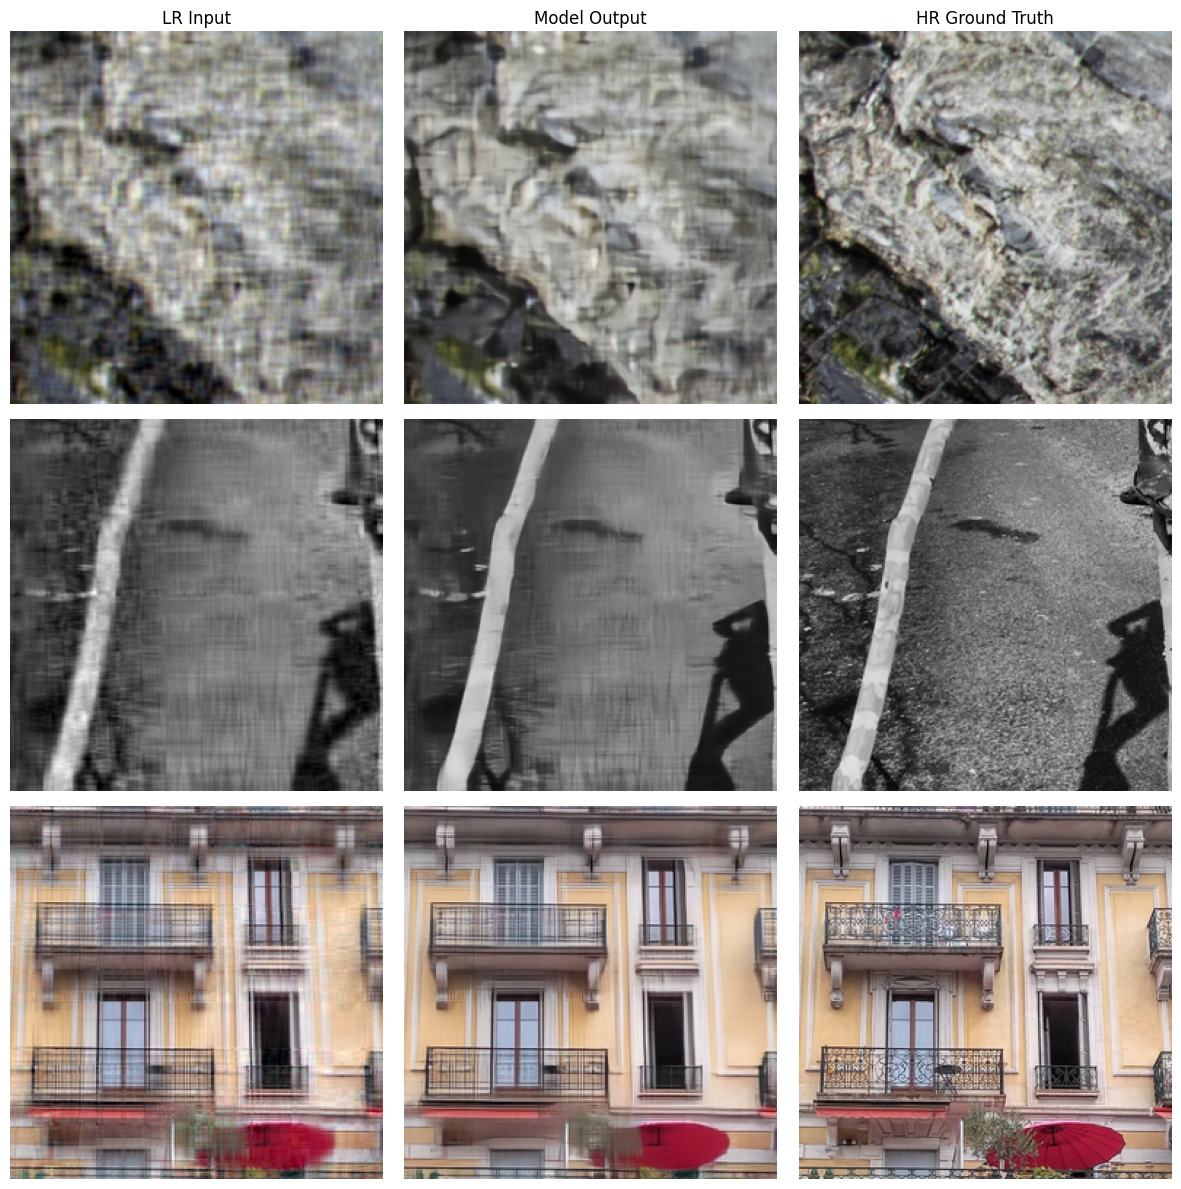

Predictions saved!


In [ ]:
# Load best model
best_ckpt = torch.load(os.path.join(ckpt_dir, 'best.pth'), map_location=device)
model.load_state_dict(best_ckpt['model'])
model.eval()
print(f'Best model: Epoch {best_ckpt["epoch"]} | PSNR: {best_ckpt["val_psnr"]:.3f} dB')

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes[0,0].set_title('LR Input',        fontsize=12)
axes[0,1].set_title('Model Output',    fontsize=12)
axes[0,2].set_title('HR Ground Truth', fontsize=12)

# Get first 3 val samples
for i in range(3):
    lr_img, hr_img, name = val_ds[i]
    lr_img = lr_img.unsqueeze(0).to(device)
    hr_img = hr_img.unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(lr_img)

    psnr_v  = compute_psnr(pred[0], hr_img[0])
    lr_np   = lr_img[0].cpu().permute(1,2,0).numpy().clip(0,1)
    pred_np = pred[0].cpu().permute(1,2,0).numpy().clip(0,1)
    hr_np   = hr_img[0].cpu().permute(1,2,0).numpy().clip(0,1)

    axes[i,0].imshow(lr_np);   axes[i,0].axis('off')
    axes[i,1].imshow(pred_np); axes[i,1].set_xlabel(f'PSNR: {psnr_v:.2f} dB'); axes[i,1].axis('off')
    axes[i,2].imshow(hr_np);   axes[i,2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'sample_predictions.png'), dpi=150)
plt.show()
print('Predictions saved!')

## Cell 16: Save Calibration Images as .npy
> Professor Tip 5: Diverse calibration from all 5 zips
> Saved as .npy arrays for NPU quantization

In [ ]:
CALIB_DIR = '/content/calibration_images'
os.makedirs(CALIB_DIR, exist_ok=True)

calib_files = []
per_zip = 40  # 40 from each zip = 200 total

for lr_dir in train_lr_dirs:
    files = gather_images(lr_dir)
    step  = max(1, len(files) // per_zip)
    calib_files.extend(files[::step][:per_zip])

# Save as JPG images
for idx, fpath in enumerate(calib_files[:200]):
    img = Image.open(fpath).convert('RGB').resize((256, 256), Image.BILINEAR)
    img.save(os.path.join(CALIB_DIR, f'calib_{idx:03d}.jpg'))

# Copy to Drive
import shutil
DRIVE_CALIB = os.path.join(SAVE_DIR, 'calibration_images')
if os.path.exists(DRIVE_CALIB):
    shutil.rmtree(DRIVE_CALIB)
shutil.copytree(CALIB_DIR, DRIVE_CALIB)

print(f'Saved {len(calib_files[:200])} calibration images as .jpg')
print(f'Location: {DRIVE_CALIB}')

Saved 200 calibration images as .jpg
Location: /content/drive/MyDrive/Lab2/outputs/calibration_images


## Cell 17: Export Final ONNX — Single File
> Based on step_1_model_saving.py reference
> Single self-contained .onnx file (no external .data)

In [ ]:
import onnx

# Load best model
best_ckpt = torch.load(os.path.join(ckpt_dir, 'best.pth'), map_location=device)

export_model = DenoiseSRNet(
    n_feat=CFG['channels'],
    n_blocks=CFG['num_blocks']
).to(device)
export_model.load_state_dict(best_ckpt['model'])
export_model.eval()
print(f'Loaded: Epoch {best_ckpt["epoch"]} | PSNR: {best_ckpt["val_psnr"]:.3f} dB')

# Export to local first
LOCAL_ONNX = '/content/sr_model.onnx'
dummy_in   = torch.randn(1, 3, CFG['input_size'], CFG['input_size'], device=device)

torch.onnx.export(
    export_model,
    dummy_in,
    LOCAL_ONNX,
    export_params=True,
    opset_version=11,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes=None,
    verbose=False
)

# Merge into single self-contained file
proto = onnx.load(LOCAL_ONNX, load_external_data=True)
onnx.save_model(
    proto,
    LOCAL_ONNX,
    save_as_external_data=False,
    all_tensors_to_one_file=False
)

# Verify
onnx.checker.check_model(onnx.load(LOCAL_ONNX))
size_mb = os.path.getsize(LOCAL_ONNX) / 1e6
print(f'ONNX size  : {size_mb:.2f} MB')
print(f'Single file: {" Yes" if size_mb > 1 else " Still split"}')

# Copy to Drive
DRIVE_ONNX = os.path.join(SAVE_DIR, 'sr_model.onnx')
shutil.copy2(LOCAL_ONNX, DRIVE_ONNX)
print(f'Saved to Drive: {DRIVE_ONNX} ')

W0407 02:41:20.063000 19851 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


Loaded: Epoch 148 | PSNR: 22.423 dB


W0407 02:41:20.582000 19851 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0407 02:41:20.583000 19851 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0407 02:41:20.585000 19851 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
W0407 02:41:20.586000 19851 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
/usr/lib/python3.1

Applied 32 of general pattern rewrite rules.
ONNX size  : 11.11 MB
Single file:  Yes
Saved to Drive: /content/drive/MyDrive/Lab2/outputs/sr_model.onnx 


## Cell 18: Validate ONNX vs PyTorch
> Verify ONNX outputs match PyTorch outputs

In [ ]:
import onnxruntime as ort

ort_session = ort.InferenceSession(LOCAL_ONNX, providers=['CPUExecutionProvider'])

# Use first val sample
sample_lr, _, _ = val_ds[0]
pt_input = sample_lr.unsqueeze(0).to(device)

with torch.no_grad():
    pt_output = export_model(pt_input).clamp(0.0, 1.0).cpu().numpy()

ort_output = ort_session.run(
    ['output'],
    {'input': pt_input.cpu().numpy()}
)[0]
ort_output = np.clip(ort_output, 0.0, 1.0)

diff = np.abs(pt_output - ort_output)
print(f'PyTorch vs ONNXRuntime')
print(f'Max diff  : {diff.max():.6f}')
print(f'Mean diff : {diff.mean():.6f}')
print(f'Match     : {" Good" if diff.max() < 1e-4 else " Check"}')

PyTorch vs ONNXRuntime
Max diff  : 0.000161
Mean diff : 0.000018
Match     :  Check


## Cell 19: Final Summary

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
onnx_size_mb = os.path.getsize(LOCAL_ONNX) / 1e6

print('=' * 65)
print('LAB 2 — COMPLETE!')
print('=' * 65)
print(f'Architecture         : DenoiseSRNet')
print(f'Total Parameters     : {total_params:,}')
print(f'Best Validation PSNR : {best_psnr:.3f} dB')
print(f'ONNX file size       : {onnx_size_mb:.2f} MB')
print(f'Best model (.pth)    : {SAVE_DIR}/best_model.pth')
print(f'ONNX model           : {DRIVE_ONNX}')
print(f'Calibration arrays   : {SAVE_DIR}/calib_arrays.zip')
print()
print('CANVAS SUBMISSION CHECKLIST:')
print('  training_script.py')
print('  onnx_to_mxq_script.py')
print('  sr_model.mxq')
print('  best_model.pth')
print()
print('NEXT STEPS (NPU Lab):')
print('  1. Download sr_model.onnx from Drive')
print('  2. Download calib_arrays.zip from Drive')
print('  3. Run step_2 → .onnx to .mxq')
print('  4. Run step_3 → PSNR on NPU')
print('  5. Submit on Canvas before April 8th!')
print('=' * 65)

LAB 2 — COMPLETE!
Architecture         : DenoiseSRNet
Total Parameters     : 2,751,747
Best Validation PSNR : 22.423 dB
ONNX file size       : 11.11 MB
Best model (.pth)    : /content/drive/MyDrive/Lab2/outputs/best_model.pth
ONNX model           : /content/drive/MyDrive/Lab2/outputs/sr_model.onnx
Calibration arrays   : /content/drive/MyDrive/Lab2/outputs/calib_arrays.zip

CANVAS SUBMISSION CHECKLIST:
  training_script.py
  onnx_to_mxq_script.py
  sr_model.mxq
  best_model.pth

NEXT STEPS (NPU Lab):
  1. Download sr_model.onnx from Drive
  2. Download calib_arrays.zip from Drive
  3. Run step_2 → .onnx to .mxq
  4. Run step_3 → PSNR on NPU
  5. Submit on Canvas before April 8th!
